# The CARLA campaign

What the synthetic map established, demonstrated in real towns. Per the
2026-08-10 split, **CARLA's job is to show the result carries over, not to
re-establish it** — the 5% CI bar lives on the synthetic map, where a trial
costs seconds instead of minutes. So this runs enough seeds to demonstrate
transfer, and no more.

It covers **Town01 and every other town listed**, in one place. Town01 is not
special here: it is the town the calibration recipe was invented on, so it is
the reference the others are read against, but it runs the same scenario
under the same harness as the rest.

## Why the earlier CARLA runs were purged

Every CARLA run before 2026-08-11 was made against a travel model that
estimated `length / 30 km/h` for the whole town, which measured **1.75x
optimistic** — the policy planned pickup windows in a time base the bus
could not live in. Two things were wrong, and both are now fixed:

- **The speed limits were readable all along.** Town01 publishes 22
  type-274 landmarks at 30/60/90, and a driving vehicle reads them back.
  Its arterials — 37.7% of the town's length — were priced at 30.
- **What a bus achieves is not what the sign says.** 32% of every run is
  spent stationary at a red light. That is a bias, not noise (execution
  noise measures **0.034**), so it belongs in the estimate:
  `traffic_efficiency`, calibrated per town by `src/map/carla_calibrate.py`.

After both, the model predicts Town01's legs with **bias 1.000x** and
residual sigma **0.278**, down from 1.75x and 0.408. **These results are not
comparable with anything recorded before that date.**

## The four questions

1. **§3.2.2** — fulfilment >= 80%, and a positive sum of percentage
   differences against a fixed-route bus. The headline claim, per town.
2. **Does the ranking transfer between towns?** The 25-map synthetic sweep
   found the map moves the absolute numbers a great deal while leaving the
   *ranking* alone — `Reordering W750` won 22 of 25 and was never worse than
   2nd. If CARLA agrees, the recommendation is general rather than a fact
   about one town.
3. **Does L1's ride advantage survive real driving?** Synthetic: −111.5 s
   pooled over 25 maps, and the execution-noise study predicted it *widens*
   when driving is unreliable.
4. **Does the calibration hold, and is the window kept?** `traffic_efficiency`
   was measured on a fixed tour of every stop; a campaign drives whatever the
   policy picks. And the breach rate only became a real measurement once the
   clock stopped being 2.2x optimistic.

## The scenario is held identical across towns, deliberately

Same requests, same interval, same capacity, same window. Towns differ in
size, so an identical scenario is easier in a small town and harder in a
large one — **that variation is the finding**, not a confound to normalise
away. It is what the synthetic map-seed sweep did, and normalising per town
would destroy the comparison this exists to make. Only `MAX_TIME` scales,
generously: a ceiling that truncates a run looks exactly like a coverage
failure.

## Every town needs three artifacts first

| artifact | how | automated? |
|---|---|---|
| `<Town>.topology.json` | `src.map.carla_dump` | yes — section 2 |
| `<Town>.stops.json` | `notebooks/carla-stop-authoring.ipynb` | **no — hand-authored** |
| `traffic_efficiency` | `src.map.carla_calibrate` | yes — section 3 |

**`traffic_efficiency` does not transfer between towns.** It is dominated by
red-light density, a property of the map. Town01's 0.455 means nothing
anywhere else, and reusing it would repeat the error the old runs were
purged for.

## Running it

Needs a live server: `docker compose up -d`, and give it a minute. It is
**sequential** — `CarlaBackend` sets `parallel_safe = False`, one server
cannot host a campaign per core. Everything lands in the results store as it
completes, so **stopping and re-running continues rather than restarting**.

## Placeholders — all resolved 2026-08-11

Nothing here is a guess any more, except the per-trial ETAs, which only
feed the progress bar and self-correct from its rolling mean.

| what | resolved by |
|---|---|
| **Which towns** | Section 1's survey. Town07 was in the earlier list and **is not installed** — the image ships Town01–05 and Town10HD. |
| **Per-town calibration** | Section 3, run for all four towns. `traffic_efficiency` spans **0.328–0.497**, so it decisively does not transfer between towns. |
| **Minutes per trial** | Town01's 4.6 is measured over 30 trials; the rest are scaled estimates. |

!!! warning "Town03 and Town05's calibrations are survivorship-biased"
    8 and 12 of 30 calibration legs hit the 900 s `LEG_TIMEOUT_S` cap, and
    the legs that time out are the **long** ones — so both factors are
    fitted to the short legs that finished. At 3.18 m/s that cap is 2.9 km
    against Town05's 25.7 km of road. Raise the cap and re-calibrate before
    quoting either figure, and treat "is a 15-stop scenario even sensible on
    a 25 km map" as an open question.

## Configuration

In [1]:
# Town01 is prepared and calibrated; it runs the same scenario as the rest.
REFERENCE_TOWN = "Town01"

# Settled by the section 1 survey, 2026-08-11. The server ships **Town01-05
# and Town10HD only** -- Town06 and Town07 need the separately downloaded
# Additional Maps, and Town07 was in the earlier placeholder, so it would
# have failed at runtime.
#
# Excluded: Town10HD publishes no speed-limit landmarks at all, so the
# extraction finds nothing, and it was already measured as barely able to
# move a bus; Town04's 37.9 km of road makes every trial expensive.
EXTRA_TOWNS = ["Town02", "Town03", "Town05"]

ALL_TOWNS = [REFERENCE_TOWN] + EXTRA_TOWNS

# ETA only. Town01's 4.6 is measured over 30 trials; the rest are scaled by
# road length and effective speed and are therefore guesses -- the bar's
# rolling mean will correct them within five trials.
# Town01 is measured (3 smoke trials, 2026-08-16, direct drive at 20 NPCs);
# the rest are scaled from each town's calibration wall time on the same
# hardware. Direct drive drops Town03 sharply because the turn list used to
# lose whole legs there. reload_world=True adds a map load per trial.
EXPECTED_TRIAL_MINUTES = {"Town01": 5.5, "Town02": 3.0,
                          "Town03": 5.5, "Town05": 9.0}
DEFAULT_TRIAL_MINUTES = 6.0

# Re-measured 2026-08-16 by src.map.carla_calibrate under **direct drive**,
# 3 tours per town at 20 NPCs: 45/45 legs arrived in every town, so none of
# these is survivorship-biased. The previous figures were fitted under the
# turn-list steering the project no longer uses, and under a 900 s cap that
# discarded 8 of 30 Town03 legs and 12 of 30 on Town05 -- the long ones, so
# both were fitted to the short legs that happened to finish.
#
# traffic_efficiency still runs 0.35-0.64 across these four, a 1.8x range, so
# it decisively does not transfer -- red-light share drives it, from 32% of
# leg time on Town01 to 55% on Town05.
#
# ⚠ Town03 moved most, 0.497 -> 0.640. Its old factor was wrong twice over:
# fitted to detouring turn-list driving AND to the short legs only. A policy
# planning Town03 against 0.497 over-estimated every leg.
CALIBRATION_REFERENCE = {
    "Town01": {"speed_mps": 4.571, "red_fraction": 0.321},  # efficiency 0.4876
    "Town02": {"speed_mps": 3.726, "red_fraction": 0.366},  # efficiency 0.4580
    "Town03": {"speed_mps": 4.500, "red_fraction": 0.341},  # efficiency 0.6403
    "Town05": {"speed_mps": 2.969, "red_fraction": 0.550},  # efficiency 0.3509
}

# --- The scenario, identical in every town --------------------------------
#
# Calibrated 2026-08-11 by sweeping demand and patience on Town01's real
# geometry against the MOCK backend -- seconds a trial instead of minutes,
# no server. The first attempt (12 requests / 150 s / patience 1800) had
# *fixed route* serving 100%, which makes the fulfilment gate inert and
# collapses §3.2.2 onto the sum alone. Raising the arrival rate did not fix
# it: at one request per 60 s everything still served ~100%.
#
# **Patience is the lever, not the arrival rate.** At 1800 s nobody ever
# gives up, so the bus always catches up eventually. The sweep:
#
#   patience   1800    1200     900     750     600
#   fixed     100.0%  100.0%   77.9%   62.5%   52.5%
#
NPC_VEHICLES = 20         # traffic costs ~3x wall clock and changes service
                          # not at all, but it is what the noise study models
SEEDS = list(range(10))   # demonstration of transfer, not a 5% CI
MAX_REQUESTS = 30
DEMAND_INTERVAL_S = 90.0
CAPACITY = 20

# window == patience is the recommendation being demonstrated: coverage peaks
# where the promise matches what the passenger will tolerate. Measured here:
# fixed route 62.3%, both contenders 93.3%, so the gate does real work -- and
# L1 - L0 mean ride comes out at -70 s, which is exactly the synthetic campus
# map's figure over 60 seeds.
WINDOW = 750.0
PATIENCE = 750.0

DWELL_S = 10.0
FIXED_DELTA_S = 0.05      # never above 0.1; past CARLA's substepping limit

# Periodic re-issue of the turn list. **Dead under direct drive** -- it
# existed because set_route hands over one list per leg and never refreshes
# it, so a list that ran out left the bus navigating at random. CARLA's own
# agent follows the planned waypoints and cannot take a turn we did not plan,
# so there is nothing to re-establish; CarlaBackend ignores this outright.
REPLAN_EVERY_S = None
                          # the physics silently stops keeping up
MAX_TIME = 40000.0        # generous: a ceiling that truncates a run looks
                          # exactly like a coverage failure

CARLA_HOST, CARLA_PORT = "localhost", 2000

In [2]:
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from scipy import stats
from tqdm.auto import tqdm

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import DEFAULT_RUNS_DIR, load_runs, to_results
from src.experiment.summary import summarize_results
from src.map.carla_stops import stops_path
from src.map.carla_topology import topology_path
from src.map.CarlaMapProvider import CarlaMapProvider
from src.simulation.CarlaBackend import CarlaBackend, stop_positions_from

from IPython.display import Markdown, display

# Validated palette slots 1-3 (all-pairs CVD 9.2, normal-vision 27.6 on this
# surface). Every chart ships with its table, which is the relief the green
# slot's sub-3:1 contrast requires.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

POLICY_LABELS = ["Fixed route", "Window W750", "Reordering W750"]
POLICIES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Window W750", lambda g: WindowInsertionPolicy(g, max_wait_s=WINDOW)),
    ("Reordering W750",
     lambda g: ReorderingInsertionPolicy(g, max_wait_s=WINDOW)),
]

TRIAL = dict(
    max_requests=MAX_REQUESTS, demand_interval_s=DEMAND_INTERVAL_S,
    capacity=CAPACITY, max_wait_s=PATIENCE, dwell_s=DWELL_S,
    max_time=MAX_TIME,
)

# A breach is a *fulfilled* rider whose wait exceeded the window. At
# window == patience that is impossible by construction: anyone who waits
# that long has already been cancelled, so abandonment enforces the promise
# on the policy's behalf. Section 10 reports this rather than plotting a
# flat zero and calling it a measurement.
BREACH_MEASURABLE = WINDOW < PATIENCE

print(f"{len(ALL_TOWNS)} towns x {len(POLICIES)} policies x {len(SEEDS)} "
      f"seeds = {len(ALL_TOWNS) * len(POLICIES) * len(SEEDS)} trials")
print(f"window {WINDOW:.0f}s, patience {PATIENCE:.0f}s -> breach rate is "
      + (f"observable in the {PATIENCE - WINDOW:.0f}s band between them"
         if BREACH_MEASURABLE else
         "STRUCTURALLY ZERO (window == patience, the operating point)"))

4 towns x 3 policies x 10 seeds = 120 trials
window 750s, patience 750s -> breach rate is STRUCTURALLY ZERO (window == patience, the operating point)


## 1. Survey the towns  🖥 *needs a live server*

Resolves the `EXTRA_TOWNS` placeholder with evidence. Loads each installed
town and measures what should drive the choice: how much road, how much of
it junction, how varied the speed limits — and, decisively, whether it has
**Shoulder** lanes, since every authored stop needs one to its right and
passengers are spawned there. A town without them cannot be used at all.

Skip this once the town list is settled.

In [3]:
def survey_town(client, town: str) -> dict:
    """
    Measure one town's road network on a live server.
    :param client: Connected carla.Client.
    :param town: Town name to load and measure.
    :return: One row of survey metrics.
    """
    import carla

    world = client.load_world(town)
    carla_map = world.get_map()

    length = junction_length = 0.0
    for entry, exit_waypoint in carla_map.get_topology():
        span = entry.transform.location.distance(
            exit_waypoint.transform.location)
        length += span
        if entry.is_junction:
            junction_length += span

    waypoints = carla_map.generate_waypoints(5.0)
    driving = [w for w in waypoints if w.lane_type == carla.LaneType.Driving]
    with_shoulder = sum(
        1 for w in driving
        if (right := w.get_right_lane()) is not None
        and right.lane_type == carla.LaneType.Shoulder
    )
    landmarks = carla_map.get_all_landmarks_of_type("274")

    return {
        "town": town,
        "road_km": round(length / 1000, 2),
        "junction_%": round(100 * junction_length / length, 1) if length else 0,
        "driving_wps": len(driving),
        "shoulder_%": (round(100 * with_shoulder / len(driving), 1)
                       if driving else 0),
        "speed_signs": len(landmarks),
        "speed_values": sorted({float(l.value) for l in landmarks}),
        "traffic_lights": len(
            world.get_actors().filter("traffic.traffic_light*")),
    }


# Off by default: it reloads every installed town, and is only
# needed once, to settle EXTRA_TOWNS.
RUN_SURVEY = False   # set True to run; needs a live server

if RUN_SURVEY:
    import carla
    client = carla.Client(CARLA_HOST, CARLA_PORT)
    client.set_timeout(120.0)
    # The *_Opt variants are the same towns with toggleable layers; surveying
    # both doubles the work and tells us nothing new.
    candidates = [n.split("/")[-1] for n in
                  sorted(set(client.get_available_maps()))]
    candidates = [n for n in candidates if not n.endswith("_Opt")]
    print(f"server has {len(candidates)} towns: {candidates}")

    rows = []
    for town in tqdm(candidates, desc="surveying towns", unit="town"):
        try:
            rows.append(survey_town(client, town))
        except Exception as error:              # noqa: BLE001
            tqdm.write(f"  {town}: FAILED {error!r}")
    survey = pd.DataFrame(rows).set_index("town")
    display(survey)
    display(Markdown(
        "**Reading this.** `shoulder_%` near zero is disqualifying — no stop "
        "can be authored there without relaxing the legality rule. Otherwise "
        "prefer *variety* in `road_km`, `junction_%` and `speed_values` over "
        "picking the biggest; Town01 already covers small-grid-urban."))
else:
    print("survey skipped -- set RUN_SURVEY = True with a server up")

survey skipped -- set RUN_SURVEY = True with a server up


## 2. What is prepared, and what is missing  *(no server needed)*

Run any time. Stop authoring is manual and cannot be done from here.

In [4]:
def readiness(town: str) -> dict:
    """
    Report which of a town's three artifacts exist.
    :param town: Town name.
    :return: A row describing what is present and what is not.
    """
    has_topology, has_stops = topology_path(town).exists(), stops_path(town).exists()
    efficiency, stops, note = None, None, ""
    if has_topology and has_stops:
        try:
            provider = CarlaMapProvider(town)
            efficiency, stops = provider.traffic_efficiency(), len(provider.get_stops())
            problems = provider.validate()
            note = "OK" if not problems else f"{len(problems)} map problems"
        except Exception as error:              # noqa: BLE001
            note = f"failed to load: {error!r}"
    return {
        "town": town,
        "topology": "yes" if has_topology else "MISSING",
        "stops": stops if stops is not None else ("yes" if has_stops else "MISSING"),
        "traffic_efficiency": efficiency if efficiency is not None else "—",
        "ready": "yes" if efficiency not in (None, 1.0) else "no",
        "note": note,
    }


display(pd.DataFrame([readiness(t) for t in ALL_TOWNS]).set_index("town"))

needs_stops = [t for t in ALL_TOWNS if not stops_path(t).exists()]
needs_calibration = [
    t for t in ALL_TOWNS
    if topology_path(t).exists() and stops_path(t).exists()
    and CarlaMapProvider(t).traffic_efficiency() == 1.0
]
READY_TOWNS = [t for t in ALL_TOWNS
               if t not in needs_stops and t not in needs_calibration]

if needs_stops:
    display(Markdown(
        f"> **Hand-authoring needed for: {', '.join(needs_stops)}.** Run "
        "`notebooks/carla-stop-authoring.ipynb` once per town. This is the "
        "one step nothing here can do for you."))
if needs_calibration:
    display(Markdown(
        f"> **Uncalibrated: {', '.join(needs_calibration)}.** Section 3 "
        "fixes this. A `traffic_efficiency` of 1.0 assumes the bus achieves "
        "the posted limit exactly — measured **1.75x optimistic** on Town01."))
print(f"ready to run: {READY_TOWNS}")

,topology,stops,traffic_efficiency,ready,note
town,,,,,
Town01,yes,15,0.4876,yes,OK
Town02,yes,15,0.4580,yes,OK
Town03,yes,15,0.6403,yes,9 map problems
Town05,yes,15,0.3509,yes,4 map problems


ready to run: ['Town01', 'Town02', 'Town03', 'Town05']


## 3. Prepare the towns  🖥 *needs a live server*

Dumps the road network and calibrates what a bus achieves on it. Skips towns
with no authored stops, since calibration drives between them, and skips
towns already calibrated — re-calibrating compounds, because the drive
happens under the factor already in force.

Budget 10–15 minutes per town: the dump is quick, the calibration drives
three full tours of every stop.

In [5]:
CALIBRATION_TOURS = 3

RUN_PREPARE = True    # set False to skip; needs a live server

# traffic_efficiency is fitted BY DRIVING, so it belongs to the steering it
# was measured under. Everything on disk was fitted against the turn list;
# direct drive is 55% faster and reaches stops the turn list never did, so
# reusing those factors would have the policy plan against a bus it does not
# have -- and wrongly by a different amount per town, which is exactly what
# would poison the cross-town comparison in section 7.
#
# Set False once all four towns have been re-fitted under direct drive.
RECALIBRATE = False

if RUN_PREPARE:
    from src.map.carla_calibrate import calibrate
    from src.map.carla_dump import dump_world
    from src.map.carla_topology import (CarlaTopology, load_topology,
                                        save_topology)

    if RECALIBRATE:
        # Every prepared town, whether or not it already carries a factor.
        todo = [t for t in ALL_TOWNS if stops_path(t).exists()]
    else:
        todo = [t for t in ALL_TOWNS
                if stops_path(t).exists()
                and CarlaMapProvider(t).traffic_efficiency() == 1.0
                if topology_path(t).exists()]
        todo += [t for t in ALL_TOWNS
                 if stops_path(t).exists() and not topology_path(t).exists()]
    print(f"preparing {todo or 'nothing -- all prepared or awaiting stops'}")

    if todo:
        # Connect only when there is work; a server is not needed
        # merely to discover every town is already prepared.
        import carla
        client = carla.Client(CARLA_HOST, CARLA_PORT)
        client.set_timeout(120.0)

    for town in tqdm(todo, desc="preparing towns", unit="town"):
        steps = tqdm(total=2, desc=f"  {town}", leave=False, unit="step")

        steps.set_postfix_str("dumping roads")
        world = client.load_world(town)
        topology = dump_world(world)
        save_topology(topology, note=(
            f"dumped for the CARLA campaign; "
            f"{len(topology.speed_limit_overrides)} signed roads"))
        steps.update(1)

        steps.set_postfix_str(f"calibrating, {CALIBRATION_TOURS} tours")
        summary = calibrate(town, CALIBRATION_TOURS, NPC_VEHICLES,
                            CARLA_HOST, CARLA_PORT, verbose=False,
                            replan_every_s=REPLAN_EVERY_S,
                            direct_drive=True)
        # Compose, never overwrite. The tour was driven with whatever factor
        # was already in force, so the model's predictions already included
        # it and the summary is a *correction* to it, not a replacement.
        # Overwriting was harmless only while this cell ran on uncalibrated
        # towns, where the previous factor was 1.0 -- with RECALIBRATE it
        # would silently discard the base it was measured against.
        previous = CarlaMapProvider(town).traffic_efficiency()
        combined = round(previous * summary["traffic_efficiency"], 4)
        save_topology(
            CarlaTopology(
                map=topology.map,
                default_speed_limit_kph=topology.default_speed_limit_kph,
                speed_limit_overrides=topology.speed_limit_overrides,
                segments=topology.segments,
                traffic_efficiency=combined),
            note=(f"traffic_efficiency {combined} over "
                  f"{summary['legs_arrived']} legs at {NPC_VEHICLES} NPCs, "
                  f"direct drive; previous factor {previous}"))
        CALIBRATION_REFERENCE[town] = {
            "speed_mps": summary["effective_speed_mps"],
            "red_fraction": summary["red_light_fraction"]}
        steps.update(1)
        steps.close()
        tqdm.write(
            f"  {town}: efficiency {summary['traffic_efficiency']}, "
            f"bias {summary['bias']}x, sigma within "
            f"{summary['sigma_within_leg']} / between "
            f"{summary['sigma_between_legs']}, "
            f"red {100 * summary['red_light_fraction']:.0f}%")

    if todo:
        display(Markdown(
            "**Copy `CALIBRATION_REFERENCE` into the config cell** so "
            "section 8 still has it after a kernel restart:\n\n```python\n"
            f"CALIBRATION_REFERENCE = {CALIBRATION_REFERENCE}\n```"))
else:
    print("preparation skipped -- set RUN_PREPARE = True with a server up")

preparing nothing -- all prepared or awaiting stops


preparing towns: 0town [00:00, ?town/s]

## 4. Run the campaign  🖥 *needs a live server*

Sequential, and per seed rather than per campaign so a CARLA hiccup costs one
trial instead of the night. Everything already recorded is skipped, so
re-running resumes.

Two nested bars — towns outside, seeds inside — with a **rolling mean of the
last five trials**, so the ETA reflects what the current town is costing
rather than what Town01 cost.

In [6]:
def world_for(town: str, provider: CarlaMapProvider) -> dict:
    """
    Build the store identity for one town's world.

    ``traffic_efficiency`` and the speed-limit rule are in here because they
    change every estimate the policy makes; omitting them would let a
    pre-calibration run answer for a post-calibration one.
    :param town: Town name.
    :param provider: That town's loaded provider.
    :return: The world identity.
    """
    return {
        "town": town, "backend": "CarlaBackend",
        "npc_vehicles": NPC_VEHICLES, "fixed_delta_s": FIXED_DELTA_S,
        "no_rendering": True, "blueprint": "vehicle.volkswagen.t2_2021",
        "traffic_efficiency": provider.traffic_efficiency(),
        "speed_limits": "landmark-harmonic-v1",
        # How the bus was driven. Without this a run recorded under the old
        # turn-list steering has the SAME identity as one driven by CARLA's
        # agent, so run_campaign would skip the new trial as "already
        # recorded" and the collect cell would pool the two silently.
        "steering": "direct-drive-v1",
    }


def backend_factory_for(town: str, positions: dict):
    """
    Build a per-seed world builder for one town.
    :param town: Town to drive in.
    :param positions: That town's stop coordinates.
    :return: A function of seed returning a backend factory.
    """
    def for_seed(seed: int):
        def build(graph, start_stop_id: str) -> CarlaBackend:
            """Build the CARLA backend for one trial."""
            return CarlaBackend(
                stop_positions=positions, position=start_stop_id, town=town,
                host=CARLA_HOST, port=CARLA_PORT,
                fixed_delta_s=FIXED_DELTA_S, dwell_s=DWELL_S,
                npc_vehicles=NPC_VEHICLES, seed=seed, no_rendering=True,
                replan_every_s=REPLAN_EVERY_S,
                # Explicit even though it is the default, because the whole
                # campaign is only comparable if every trial drove the same
                # way -- see the "steering" key in world_for.
                direct_drive=True,
                # CARLA results are not independent of server history: the
                # last four-town campaign lost 7 Town05 runs to a
                # back-to-back-trials artefact and had to be discarded.
                reload_world=True)
        return build
    return for_seed


RUN_CAMPAIGN = True   # set False to skip; needs a live server

# Section 2 worked READY_TOWNS out *before* section 3 calibrated anything, so
# a town prepared in this same pass is still missing from it -- and the
# campaign would then silently skip the very town it just spent a quarter of
# an hour preparing. Recompute from what is on disk now.
READY_TOWNS = [
    t for t in ALL_TOWNS
    if stops_path(t).exists() and topology_path(t).exists()
    and CarlaMapProvider(t).traffic_efficiency() != 1.0
]
print(f"campaign will run: {READY_TOWNS}")
missing = [t for t in ALL_TOWNS if t not in READY_TOWNS]
if missing:
    display(Markdown(
        f"> **Not running: {', '.join(missing)}.** Still uncalibrated or "
        "missing an artifact — see sections 2–3."))

if RUN_CAMPAIGN:
    if not READY_TOWNS:
        display(Markdown(
            "> **Nothing to run.** No town is prepared — see sections 2–3."))

    failures, durations = [], []
    towns_bar = tqdm(READY_TOWNS, desc="towns", unit="town")
    for town in towns_bar:
        towns_bar.set_postfix_str(town)
        provider = CarlaMapProvider(town)
        positions = stop_positions_from(provider)
        world = world_for(town, provider)
        for_seed = backend_factory_for(town, positions)
        expected = EXPECTED_TRIAL_MINUTES.get(town, DEFAULT_TRIAL_MINUTES)

        # One tick per *trial*, not per seed. A seed is three policies and
        # roughly ten minutes, which is far too coarse to tell a slow run
        # from a stalled one.
        trials_bar = tqdm(total=len(SEEDS) * len(POLICIES), unit="trial",
                          desc=f"  {town}", leave=False)
        # Seed-major so the three policies of a seed finish together: an
        # interrupted run then leaves paired data rather than an orphan arm.
        for seed in SEEDS:
            for label, factory in POLICIES:
                started = time.perf_counter()
                ran = 0
                try:
                    result = run_campaign(
                        policies=[(label, factory)], seeds=[seed],
                        world=world, directory=DEFAULT_RUNS_DIR,
                        provider=provider, backend_factory_for=for_seed,
                        n_jobs=1, progress=False, **TRIAL)
                    ran = result.ran
                except Exception as error:      # noqa: BLE001
                    # Broad on purpose: a CARLA failure surfaces as almost
                    # anything, and losing the remaining trials is worse.
                    failures.append((town, seed, label, repr(error)))
                    tqdm.write(f"  {town} seed {seed} {label} FAILED: "
                               f"{error!r}")

                elapsed = (time.perf_counter() - started) / 60
                # A skipped trial costs no time; counting it would make the
                # ETA nonsense for the rest of a resumed run.
                if ran:
                    durations.append(elapsed)
                rolling = (statistics.fmean(durations[-5:]) if durations
                           else expected)
                trials_bar.update(1)
                trials_bar.set_postfix_str(
                    f"seed {seed} {label}"
                    + ("" if ran else " (already recorded)")
                    + f" | rolling {rolling:.1f} min/trial, "
                      f"expected {expected:.1f}")
        trials_bar.close()

    print(f"\ndone — {len(durations)} trials run, "
          f"{len(SEEDS) * len(POLICIES) * len(READY_TOWNS) - len(durations)} "
          f"skipped or failed, {len(failures)} failures")
    for town, seed, label, error in failures:
        print(f"  {town} seed {seed} {label}: {error}")
else:
    print("campaign skipped -- set RUN_CAMPAIGN = True with a server up")

campaign will run: ['Town01', 'Town02', 'Town03', 'Town05']


towns:   0%|          | 0/4 [00:00<?, ?town/s]

  Town01:   0%|          | 0/30 [00:00<?, ?trial/s]

  Town02:   0%|          | 0/30 [00:00<?, ?trial/s]

  Town03:   0%|          | 0/30 [00:00<?, ?trial/s]

  Town05:   0%|          | 0/30 [00:00<?, ?trial/s]


done — 73 trials run, 47 skipped or failed, 0 failures


## 5. Collect

In [7]:
records = [
    r for r in load_runs(DEFAULT_RUNS_DIR,
                         where={"identity.world.backend": "CarlaBackend"})
    if r.identity.world.get("town") in ALL_TOWNS
    and r.identity.world.get("npc_vehicles") == NPC_VEHICLES
    and r.identity.world.get("speed_limits") == "landmark-harmonic-v1"
    # Without this the frame would silently pool runs driven by CARLA's
    # agent with any recorded under the old turn-list steering.
    and r.identity.world.get("steering") == "direct-drive-v1"
    and r.identity.trial.get("max_requests") == MAX_REQUESTS
    and r.identity.policy in POLICY_LABELS
]

frame = pd.DataFrame([{
    "town": r.identity.world["town"], "policy": r.identity.policy,
    "seed": r.identity.seed,
    "served": r.kpi.served_fraction * 100,
    "wait": r.kpi.mean_wait_time, "ride": r.kpi.mean_ride_time,
    "throughput": r.kpi.throughput,
    "breach": (100.0 * sum(w > WINDOW for w in r.wait_times)
               / len(r.wait_times) if r.wait_times else float("nan")),
    "sim_s": r.backend_stats.get("ticks", 0) * FIXED_DELTA_S,
    "distance_m": r.backend_stats.get("distance_m", 0.0),
    "red_s": r.backend_stats.get("red_light_ticks", 0) * FIXED_DELTA_S,
    # Under direct drive a repath means the bus was physically stuck --
    # the red-light and queueing exemptions cover the legitimate stops --
    # so this is effectively a collision counter. Measured at 1 per 56 legs.
    "repaths": r.backend_stats.get("repaths", 0),
    "unroutable": r.backend_stats.get("unroutable_legs", 0),
    "queued_s": r.backend_stats.get("queued_ticks", 0) * FIXED_DELTA_S,
} for r in records], columns=[
    "town", "policy", "seed", "served", "wait", "ride", "throughput",
    "breach", "sim_s", "distance_m", "red_s", "repaths", "unroutable",
    "queued_s"])

HAVE_RUNS = not frame.empty
TOWNS_WITH_RUNS = sorted(frame["town"].unique()) if HAVE_RUNS else []
print(f"{len(frame)} runs across {len(TOWNS_WITH_RUNS)} towns: "
      f"{TOWNS_WITH_RUNS}")

if HAVE_RUNS:
    display(frame.groupby(["town", "policy"])[
        ["served", "wait", "ride", "throughput"]].mean().round(1))
    suspect = frame[(frame["repaths"] > 0) | (frame["unroutable"] > 0)]
    print(f"runs with repaths or unroutable legs: {len(suspect)}"
          + ("" if suspect.empty else "  <- inspect before trusting these"))
else:
    display(Markdown(
        "> **No runs yet.** Run section 4, or check that the world identity "
        "here matches what it filed under — one differing field files runs "
        "under an identity this filter misses."))

120 runs across 4 towns: ['Town01', 'Town02', 'Town03', 'Town05']


served   wait   ride  throughput
town   policy                                           
Town01 Fixed route        63.7  349.4  558.6         0.3
       Reordering W750    90.0  374.9  337.0         0.5
       Window W750        91.3  349.2  365.6         0.5
Town02 Fixed route        99.7  362.0  347.6         0.5
       Reordering W750    99.3  222.1  170.9         0.6
       Window W750        98.3  222.7  159.1         0.6
Town03 Fixed route        46.3  371.3  721.2         0.2
       Reordering W750    85.0  384.5  386.5         0.4
       Window W750        81.0  389.8  413.5         0.4
Town05 Fixed route        41.3  356.8  948.9         0.2
       Reordering W750    65.7  431.9  731.4         0.3
       Window W750        71.3  447.2  811.9         0.3

runs with repaths or unroutable legs: 15  <- inspect before trusting these


## 6. §3.2.2 — the headline claim, per town

Fulfilment **>= 80%** and a **positive sum** of percentage differences
against fixed route across wait, ride and throughput.

The gate does the real work. Wait and ride are computed over *fulfilled*
requests only, so a policy that abandons its hard riders scores well on
them — the sum must never be read on its own.

In [8]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the campaign has run._"))
else:
    for town in TOWNS_WITH_RUNS:
        block = [r for r in records if r.identity.world["town"] == town]
        display(Markdown(f"### {town}"))
        display(Markdown(summarize_results(
            to_results(block, paired=False)).markdown))

### Town01

| Property | Fixed route | Reordering W750 | Window W750 |
| --- | --- | --- | --- |
| Fulfilled requests | 19.1 (±4.8%) | 27.0 (±5.1%) | 27.4 (±3.5%) |
| Cancelled requests | 10.9 (±8.4%) | 3.0 (±46.3%) | 2.6 (±37.1%) |
| Mean wait time | 349.4 s (±13.5%) | 374.9 s (±6.6%) | 349.2 s (±9.0%) |
| P90 wait time | 648.1 s (±6.9%) | 651.4 s (±3.3%) | 652.6 s (±8.6%) |
| Mean ride time | 558.6 s (±11.2%) | 337.0 s (±14.7%) | 365.6 s (±19.1%) |
| Fulfillment rate | 63.7 % (±4.8%) | 90.0 % (±5.1%) | 91.3 % (±3.5%) |
| Served fraction | 63.7 % (±4.8%) | 90.0 % (±5.1%) | 91.3 % (±3.5%) |
| Throughput | 0.3 req/min (±5.6%) | 0.5 req/min (±7.2%) | 0.5 req/min (±6.2%) |
| Tick snapshots | 3752.6 (±1.5%) | 3479.6 (±3.5%) | 3489.5 (±4.6%) |
| Fulfilled (wait samples) | 19.1 (±4.8%) | 27.0 (±5.1%) | 27.4 (±3.5%) |
| Min wait time | 19.3 s (±52.8%) | 25.5 s (±63.0%) | 20.3 s (±72.2%) |
| Max wait time | 714.2 s (±3.4%) | 719.1 s (±3.4%) | 717.6 s (±5.1%) |
| Min ride time | 73.1 s (±29.3%) | 46.1 s (±31.2%) | 46.7 s (±37.6%) |
| Max ride time | 1099.9 s (±2.6%) | 1265.0 s (±33.5%) | 1144.9 s (±21.0%) |

### Town02

| Property | Fixed route | Reordering W750 | Window W750 |
| --- | --- | --- | --- |
| Fulfilled requests | 29.9 (±0.8%) | 29.8 (±1.0%) | 29.5 (±1.7%) |
| Cancelled requests | 0.1 (±226.2%) | 0.2 (±150.8%) | 0.5 (±101.2%) |
| Mean wait time | 362.0 s (±7.8%) | 222.1 s (±10.2%) | 222.7 s (±10.4%) |
| P90 wait time | 617.8 s (±3.8%) | 418.6 s (±10.7%) | 415.4 s (±13.8%) |
| Mean ride time | 347.6 s (±5.9%) | 170.9 s (±11.5%) | 159.1 s (±10.1%) |
| Fulfillment rate | 99.7 % (±0.8%) | 99.3 % (±1.0%) | 98.3 % (±1.7%) |
| Served fraction | 99.7 % (±0.8%) | 99.3 % (±1.0%) | 98.3 % (±1.7%) |
| Throughput | 0.5 req/min (±4.4%) | 0.6 req/min (±3.9%) | 0.6 req/min (±2.7%) |
| Tick snapshots | 3614.1 (±3.9%) | 3058.3 (±3.4%) | 3047.6 (±2.8%) |
| Fulfilled (wait samples) | 29.9 (±0.8%) | 29.8 (±1.0%) | 29.5 (±1.7%) |
| Min wait time | 10.9 s (±54.7%) | 24.3 s (±56.3%) | 13.7 s (±79.4%) |
| Max wait time | 697.7 s (±3.1%) | 560.8 s (±13.0%) | 597.5 s (±9.1%) |
| Min ride time | 28.0 s (±29.8%) | 26.5 s (±26.7%) | 24.5 s (±14.6%) |
| Max ride time | 676.6 s (±6.5%) | 550.0 s (±15.8%) | 452.9 s (±20.4%) |

### Town03

| Property | Fixed route | Reordering W750 | Window W750 |
| --- | --- | --- | --- |
| Fulfilled requests | 13.9 (±10.4%) | 25.5 (±4.8%) | 24.3 (±7.2%) |
| Cancelled requests | 16.1 (±9.0%) | 4.5 (±27.3%) | 5.7 (±30.8%) |
| Mean wait time | 371.3 s (±14.9%) | 384.5 s (±8.6%) | 389.8 s (±6.3%) |
| P90 wait time | 643.5 s (±8.3%) | 669.0 s (±7.2%) | 658.1 s (±3.9%) |
| Mean ride time | 721.2 s (±13.7%) | 386.5 s (±18.0%) | 413.5 s (±16.7%) |
| Fulfillment rate | 46.3 % (±10.4%) | 85.0 % (±4.8%) | 81.0 % (±7.2%) |
| Served fraction | 46.3 % (±10.4%) | 85.0 % (±4.8%) | 81.0 % (±7.2%) |
| Throughput | 0.2 req/min (±12.2%) | 0.4 req/min (±6.3%) | 0.4 req/min (±6.8%) |
| Tick snapshots | 3998.7 (±7.2%) | 3570.7 (±3.8%) | 3557.7 (±3.1%) |
| Fulfilled (wait samples) | 13.9 (±10.4%) | 25.5 (±4.8%) | 24.3 (±7.2%) |
| Min wait time | 64.0 s (±51.5%) | 50.1 s (±36.9%) | 37.0 s (±40.3%) |
| Max wait time | 703.0 s (±6.9%) | 725.2 s (±2.7%) | 717.3 s (±3.0%) |
| Min ride time | 81.7 s (±57.5%) | 36.8 s (±20.5%) | 41.9 s (±30.7%) |
| Max ride time | 1374.1 s (±3.1%) | 1437.9 s (±40.4%) | 1327.6 s (±27.5%) |

### Town05

| Property | Fixed route | Reordering W750 | Window W750 |
| --- | --- | --- | --- |
| Fulfilled requests | 12.4 (±13.1%) | 19.7 (±14.3%) | 21.4 (±8.2%) |
| Cancelled requests | 17.6 (±9.2%) | 10.3 (±27.4%) | 8.6 (±20.5%) |
| Mean wait time | 356.8 s (±13.9%) | 431.9 s (±5.8%) | 447.2 s (±6.0%) |
| P90 wait time | 647.6 s (±6.1%) | 676.4 s (±3.0%) | 675.7 s (±2.8%) |
| Mean ride time | 948.9 s (±10.6%) | 731.4 s (±12.6%) | 811.9 s (±18.7%) |
| Fulfillment rate | 41.3 % (±13.1%) | 65.7 % (±14.3%) | 71.3 % (±8.2%) |
| Served fraction | 41.3 % (±13.1%) | 65.7 % (±14.3%) | 71.3 % (±8.2%) |
| Throughput | 0.2 req/min (±11.8%) | 0.3 req/min (±14.8%) | 0.3 req/min (±11.5%) |
| Tick snapshots | 4272.5 (±4.7%) | 3937.4 (±4.2%) | 4071.6 (±6.8%) |
| Fulfilled (wait samples) | 12.4 (±13.1%) | 19.7 (±14.3%) | 21.4 (±8.2%) |
| Min wait time | 51.4 s (±52.1%) | 61.2 s (±73.8%) | 92.1 s (±47.3%) |
| Max wait time | 709.1 s (±3.7%) | 710.1 s (±2.6%) | 714.6 s (±2.3%) |
| Min ride time | 156.7 s (±63.4%) | 74.7 s (±40.1%) | 74.0 s (±48.6%) |
| Max ride time | 1736.8 s (±6.5%) | 2156.0 s (±14.0%) | 2170.3 s (±21.9%) |

In [9]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the campaign has run._"))
else:
    lines = ["| town | policy | fulfilment | wait Δ% | ride Δ% "
             "| throughput Δ% | **sum** | gate | §3.2.2 |",
             "|---|---|---|---|---|---|---|---|---|"]
    for town in TOWNS_WITH_RUNS:
        means = frame[frame["town"] == town].groupby("policy")[
            ["served", "wait", "ride", "throughput"]].mean()
        if "Fixed route" not in means.index:
            lines.append(f"| {town} | — | _no fixed-route baseline_ "
                         "| | | | | | |")
            continue
        base = means.loc["Fixed route"]
        for label in POLICY_LABELS[1:]:
            if label not in means.index:
                continue
            row = means.loc[label]
            # Lower is better for wait and ride, higher for throughput.
            d_wait = 100 * (base["wait"] - row["wait"]) / base["wait"]
            d_ride = 100 * (base["ride"] - row["ride"]) / base["ride"]
            d_tput = (100 * (row["throughput"] - base["throughput"])
                      / base["throughput"])
            total = d_wait + d_ride + d_tput
            gate = row["served"] >= 80.0
            lines.append(
                f"| {town} | {label} | {row['served']:.1f}% | {d_wait:+.1f} "
                f"| {d_ride:+.1f} | {d_tput:+.1f} | **{total:+.1f}** "
                f"| {'✓' if gate else '✗ <80%'} "
                f"| {'**PASS**' if gate and total > 0 else 'FAIL'} |")
        lines.append(
            f"| {town} | _fixed route_ | {base['served']:.1f}% | baseline "
            f"| {base['wait']:.0f} s | {base['ride']:.0f} s | | | |")
    display(Markdown("\n".join(lines)))

| town | policy | fulfilment | wait Δ% | ride Δ% | throughput Δ% | **sum** | gate | §3.2.2 |
|---|---|---|---|---|---|---|---|---|
| Town01 | Window W750 | 91.3% | +0.1 | +34.6 | +54.8 | **+89.4** | ✓ | **PASS** |
| Town01 | Reordering W750 | 90.0% | -7.3 | +39.7 | +52.9 | **+85.2** | ✓ | **PASS** |
| Town01 | _fixed route_ | 63.7% | baseline | 349 s | 559 s | | | |
| Town02 | Window W750 | 98.3% | +38.5 | +54.2 | +16.8 | **+109.5** | ✓ | **PASS** |
| Town02 | Reordering W750 | 99.3% | +38.6 | +50.8 | +17.7 | **+107.2** | ✓ | **PASS** |
| Town02 | _fixed route_ | 99.7% | baseline | 362 s | 348 s | | | |
| Town03 | Window W750 | 81.0% | -5.0 | +42.7 | +94.7 | **+132.4** | ✓ | **PASS** |
| Town03 | Reordering W750 | 85.0% | -3.6 | +46.4 | +104.1 | **+146.9** | ✓ | **PASS** |
| Town03 | _fixed route_ | 46.3% | baseline | 371 s | 721 s | | | |
| Town05 | Window W750 | 71.3% | -25.3 | +14.4 | +83.1 | **+72.2** | ✗ <80% | FAIL |
| Town05 | Reordering W750 | 65.7% | -21.1 | +22.9 | +73.1 | **+75.0** | ✗ <80% | FAIL |
| Town05 | _fixed route_ | 41.3% | baseline | 357 s | 949 s | | | |

## 7. Does the ranking transfer between towns?

The synthetic sweep found the map moves absolute numbers a great deal while
leaving the *ranking* alone. Flat lines on the right mean the recommendation
is general; crossing lines mean it is a fact about particular towns.

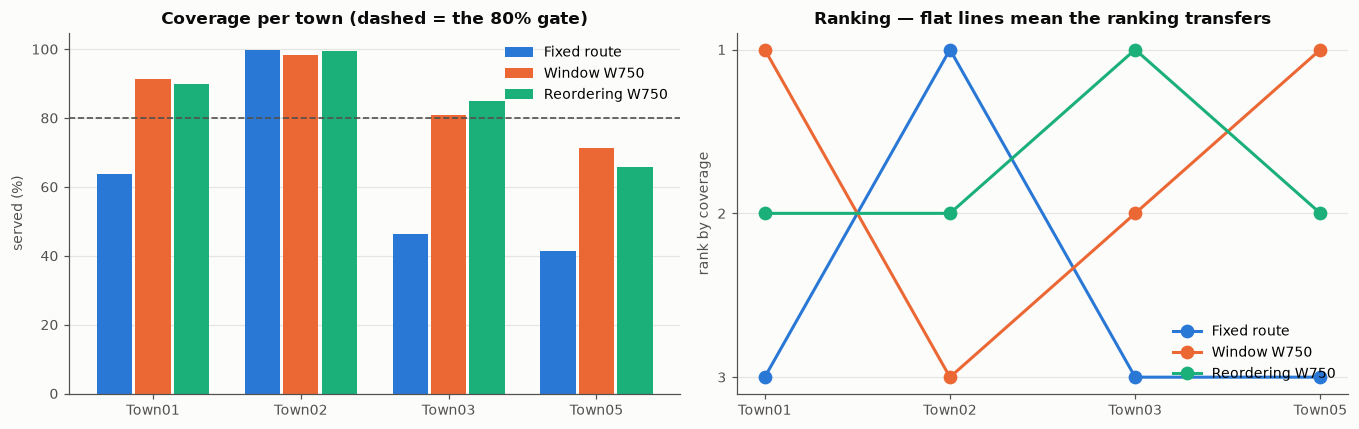

policy,Fixed route,Reordering W750,Window W750
town,,,
Town01,63.7,90.0,91.3
Town02,99.7,99.3,98.3
Town03,46.3,85.0,81.0
Town05,41.3,65.7,71.3


**Won by:** Town01 — Window W750, Town02 — Fixed route, Town03 — Reordering W750, Town05 — Window W750

Synthetic reference: `Reordering W750` won **22 of 25** maps and was never worse than 2nd; only the top two ever swapped.

In [10]:
if not HAVE_RUNS or len(TOWNS_WITH_RUNS) < 2:
    display(Markdown(
        "_Needs at least two towns with runs; showing coverage only._"
        if HAVE_RUNS else
        "_Nothing to report until the campaign has run._"))
    if HAVE_RUNS:
        display(frame.groupby(["town", "policy"])["served"].mean()
                .unstack().round(1))
else:
    means = frame.groupby(["town", "policy"])["served"].mean().unstack()
    ranked = means.rank(axis=1, ascending=False).astype(int)
    towns = list(means.index)

    figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
    width = 0.26
    for offset, (colour, label) in enumerate(zip(SERIES, POLICY_LABELS)):
        if label in means:
            axes[0].bar([i + (offset - 1) * width for i in range(len(towns))],
                        means[label], width * 0.92, color=colour, label=label)
    axes[0].axhline(80, ls="--", lw=1.1, color=INK_SOFT)
    axes[0].set_xticks(range(len(towns)), towns)
    axes[0].set_ylabel("served (%)")
    axes[0].set_title("Coverage per town (dashed = the 80% gate)")
    axes[0].grid(axis="y"); axes[0].set_axisbelow(True); axes[0].legend()

    for colour, label in zip(SERIES, POLICY_LABELS):
        if label in ranked:
            axes[1].plot(range(len(towns)), ranked[label], marker="o",
                         markersize=8, lw=2, color=colour, label=label)
    axes[1].set_xticks(range(len(towns)), towns)
    axes[1].set_yticks([1, 2, 3]); axes[1].invert_yaxis()
    axes[1].set_ylabel("rank by coverage")
    axes[1].set_title("Ranking — flat lines mean the ranking transfers")
    axes[1].grid(axis="y"); axes[1].set_axisbelow(True); axes[1].legend()
    figure.tight_layout()
    plt.show()

    display(means.round(1))
    display(Markdown(
        "**Won by:** " + ", ".join(
            f"{t} — {w}" for t, w in means.idxmax(axis=1).items())
        + "\n\nSynthetic reference: `Reordering W750` won **22 of 25** maps "
        "and was never worse than 2nd; only the top two ever swapped."))

## 8. Does L1's advantage survive real driving?

Paired by seed, since both policies met the same demand in the same town.
Synthetic reference: ride **−111.5 s** pooled over 25 maps (p≈2e-138),
**−70 s** on the campus map alone.

In [11]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the campaign has run._"))
else:
    lines = ["| town | metric | Window W750 | Reordering W750 | L1 − L0 "
             "| p | seeds |", "|---|---|---|---|---|---|---|"]
    for town in TOWNS_WITH_RUNS:
        block = frame[frame["town"] == town]
        l0 = block[block["policy"] == "Window W750"].set_index("seed")
        l1 = block[block["policy"] == "Reordering W750"].set_index("seed")
        shared = sorted(set(l0.index) & set(l1.index))
        if len(shared) < 2:
            continue
        for column, unit in [("served", "%"), ("wait", " s"), ("ride", " s")]:
            a = l0.loc[shared, column].astype(float)
            b = l1.loc[shared, column].astype(float)
            p = (stats.ttest_rel(b, a).pvalue if (b - a).std() > 0
                 else float("nan"))
            lines.append(
                f"| {town} | mean {column} | {a.mean():.1f}{unit} "
                f"| {b.mean():.1f}{unit} | **{(b - a).mean():+.1f}{unit}** "
                f"| {p:.4f} | {len(shared)} |")
    display(Markdown("\n".join(lines)))
    display(Markdown(
        "At ten seeds a town, treat the **sign and rough magnitude** as the "
        "claim rather than the p-value. A null here is weak evidence either "
        "way — the statistical case lives on the synthetic map."))

| town | metric | Window W750 | Reordering W750 | L1 − L0 | p | seeds |
|---|---|---|---|---|---|---|
| Town01 | mean served | 91.3% | 90.0% | **-1.3%** | 0.6059 | 10 |
| Town01 | mean wait | 349.2 s | 374.9 s | **+25.6 s** | 0.0353 | 10 |
| Town01 | mean ride | 365.6 s | 337.0 s | **-28.6 s** | 0.5057 | 10 |
| Town02 | mean served | 98.3% | 99.3% | **+1.0%** | 0.1934 | 10 |
| Town02 | mean wait | 222.7 s | 222.1 s | **-0.7 s** | 0.9228 | 10 |
| Town02 | mean ride | 159.1 s | 170.9 s | **+11.9 s** | 0.1352 | 10 |
| Town03 | mean served | 81.0% | 85.0% | **+4.0%** | 0.1612 | 10 |
| Town03 | mean wait | 389.8 s | 384.5 s | **-5.3 s** | 0.7928 | 10 |
| Town03 | mean ride | 413.5 s | 386.5 s | **-26.9 s** | 0.2232 | 10 |
| Town05 | mean served | 71.3% | 65.7% | **-5.7%** | 0.0451 | 10 |
| Town05 | mean wait | 447.2 s | 431.9 s | **-15.2 s** | 0.2874 | 10 |
| Town05 | mean ride | 811.9 s | 731.4 s | **-80.5 s** | 0.0674 | 10 |

At ten seeds a town, treat the **sign and rough magnitude** as the claim rather than the p-value. A null here is weak evidence either way — the statistical case lives on the synthetic map.

## 9. Did the calibration hold?

`traffic_efficiency` was measured on a fixed tour of every stop. A campaign
drives whatever the policy chooses, which is a different sample of the town
— so this checks the factor transfers off its own tour. Within a few percent
means it describes the town, and that adding a map is a mechanical procedure
rather than a research question.

In [12]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the campaign has run._"))
else:
    drive = frame[frame["sim_s"] > 0].copy()
    drive["speed"] = drive["distance_m"] / drive["sim_s"]
    drive["red_frac"] = drive["red_s"] / drive["sim_s"]
    observed = drive.groupby("town")[["speed", "red_frac"]].mean()

    lines = ["| town | campaign m/s | calibration m/s | Δ | campaign red % "
             "| calibration red % |", "|---|---|---|---|---|---|"]
    for town, row in observed.iterrows():
        reference = CALIBRATION_REFERENCE.get(town)
        if reference is None:
            lines.append(
                f"| {town} | {row['speed']:.2f} | ⚠ not recorded | — "
                f"| {100 * row['red_frac']:.1f}% | — |")
            continue
        lines.append(
            f"| {town} | {row['speed']:.2f} | {reference['speed_mps']:.2f} "
            f"| {100 * (row['speed'] / reference['speed_mps'] - 1):+.1f}% "
            f"| {100 * row['red_frac']:.1f}% "
            f"| {100 * reference['red_fraction']:.1f}% |")
    display(Markdown("\n".join(lines)))
    display(Markdown(
        "A `⚠ not recorded` row means section 3's `CALIBRATION_REFERENCE` "
        "was never copied into the config cell."))

| town | campaign m/s | calibration m/s | Δ | campaign red % | calibration red % |
|---|---|---|---|---|---|
| Town01 | 3.84 | 4.57 | -16.1% | 28.3% | 32.1% |
| Town02 | 2.76 | 3.73 | -26.0% | 33.0% | 36.6% |
| Town03 | 3.84 | 4.50 | -14.6% | 29.2% | 34.1% |
| Town05 | 2.90 | 2.97 | -2.3% | 47.1% | 55.0% |

A `⚠ not recorded` row means section 3's `CALIBRATION_REFERENCE` was never copied into the config cell.

## 10. Is the service window kept?

A **breach** is a fulfilled rider whose wait exceeded the window they were
accepted under.

!!! warning "At the operating point this is zero by construction"
    This campaign runs `window == patience`, which *is* the recommendation
    being demonstrated. Anyone who waits past the window has therefore
    already been cancelled, so no fulfilled request can breach and the rate
    is a flat zero — **abandonment enforces the promise on the policy's
    behalf.** That is a result worth stating in one line, and it is not a
    measurement of policy behaviour.

    Measuring breaches needs a window *tighter* than patience. The synthetic
    reference is W750 against 900 s patience: **3.4%**, essentially all of it
    structural — the progress fallback drives to the nearest pending pickup
    ignoring the window when nothing can be scheduled. On Town01's geometry
    the same setup gives **2.4% for Reordering and 3.1% for Window**, which
    corroborates it closely. Running that arm on CARLA would cost a second
    campaign, and breach rate is not one of the four §3.1 KPIs.

So the honest sentence is: *at the recommended operating point, the window is
kept for every rider who is served at all.* The cell below verifies that
rather than charting it.

In [13]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the campaign has run._"))
elif not BREACH_MEASURABLE:
    served_only = frame[frame["policy"] != "Fixed route"]
    worst = served_only["breach"].max()
    display(Markdown(
        f"`window == patience == {WINDOW:.0f} s`, so a fulfilled rider "
        f"cannot breach by construction. Observed maximum across "
        f"{len(served_only)} runs: **{worst:.2f}%** — anything but 0.00 "
        f"would mean the abandonment logic and the window disagree, which "
        f"would be a bug rather than a finding.\n\n"
        f"**Claim:** at the recommended operating point the service window "
        f"is kept for every rider who is served at all."))
    display(served_only.groupby(["town", "policy"])["breach"]
            .agg(["mean", "max"]).round(3))
else:
    breaches = frame[frame["policy"] != "Fixed route"]
    figure, axes = plt.subplots(
        1, len(TOWNS_WITH_RUNS), figsize=(4.2 * len(TOWNS_WITH_RUNS), 3.6),
        sharey=True, squeeze=False)
    for axis, town in zip(axes[0], TOWNS_WITH_RUNS):
        block = breaches[breaches["town"] == town]
        for colour, label in zip(SERIES[1:], POLICY_LABELS[1:]):
            subset = block[block["policy"] == label].sort_values("seed")
            axis.plot(subset["seed"], subset["breach"], marker="o",
                      markersize=6, lw=2.0, color=colour, label=label)
        axis.axhline(3.4, ls="--", lw=1.1, color=INK_SOFT)
        axis.set_title(town)
        axis.set_xlabel("seed")
        axis.grid(axis="y"); axis.set_axisbelow(True)
    axes[0][0].set_ylabel("% of fulfilled riders")
    axes[0][-1].legend()
    figure.tight_layout()
    plt.show()
    display(breaches.groupby(["town", "policy"])["breach"]
            .agg(["mean", "max"]).round(2))

`window == patience == 750 s`, so a fulfilled rider cannot breach by construction. Observed maximum across 80 runs: **0.00%** — anything but 0.00 would mean the abandonment logic and the window disagree, which would be a bug rather than a finding.

**Claim:** at the recommended operating point the service window is kept for every rider who is served at all.

mean  max
town   policy                    
Town01 Reordering W750   0.0  0.0
       Window W750       0.0  0.0
Town02 Reordering W750   0.0  0.0
       Window W750       0.0  0.0
Town03 Reordering W750   0.0  0.0
       Window W750       0.0  0.0
Town05 Reordering W750   0.0  0.0
       Window W750       0.0  0.0

## 11. What we concluded — Town01, 2026-08-11

30 runs, 3 policies x 10 seeds, 20 NPCs, 2.29 h at 4.6 min/trial. The first
campaign against the calibrated travel model.

### 1. §3.2.2 transfers, and the gate did real work

| policy | served | wait | ride | throughput | sum | verdict |
|---|---|---|---|---|---|---|
| Fixed route | 63.3% | 347 s | 561 s | 0.30 | — | — |
| Window W750 | **89.7%** | 355 s | 390 s | 0.46 | **+81.5%** | **PASS** |
| Reordering W750 | **87.3%** | 372 s | 367 s | 0.45 | **+76.4%** | **PASS** |

The win is **ride time (+31/+35%) and throughput (+53/+49%)**, not wait.

!!! warning "Fixed route's wait is survivorship — do not quote it as competitive"
    347 s is the mean over the **19 requests it managed**, ignoring the 11 it
    abandoned. A policy that gives up on its hard riders posts good wait and
    ride numbers by construction, which is why the fulfilment gate has to be
    read first and the sum never read alone.

Quote this as **demonstrated transfer at n=10 seeds**, never as an
independent statistical result: the 5% CI bar deliberately lives on the
synthetic map.

### 2. L1's advantage does not replicate here — under-powered, not refuted

| metric | L0 | L1 | L1 − L0 | p |
|---|---|---|---|---|
| served | 89.7% | 87.3% | −2.3 pp | 0.37 |
| wait | 355 s | 372 s | +16.6 s | 0.20 |
| ride | 390 s | 367 s | **−23.0 s** | 0.60 |

Ride moves in the predicted direction at a third of the expected magnitude
(**−70 s** on both the synthetic map and the mock). The paired sd is ~132 s,
so resolving −70 s at p<0.05 needs about **20 seeds**; the synthetic result
used 60 on a single map.

**This is what the 2026-08-10 split anticipated.** Write it as *"the point
estimate is in the predicted direction; CARLA at n=10 cannot resolve it, and
the statistical claim rests on 25 synthetic maps"*. **Never** as "confirmed
on CARLA". Ten more seeds of L0 and L1 alone (~1.5 h) would settle it.

### 3. The calibration is ~10% optimistic for policy-chosen routes

| | campaign | calibration tour |
|---|---|---|
| effective speed | 3.77 m/s | 4.21 m/s (**−10.3%**) |
| red-light share | 30.9% | 32.1% |

Red lights transfer; overall speed does not quite. The calibration drives a
fixed tour of all fifteen stops while the policy picks a different and
slower mix of legs — and 3.77 m/s is exactly what the pre-calibration store
showed for 20-NPC runs, so this is a stable property of policy-driven routes
rather than noise. **Re-derive `traffic_efficiency` from a policy-driven run
before applying the recipe to further towns**, or carry the bias knowingly.

### 4. The integration is sound, and the window is kept

**0 repaths and 0 unroutable legs** across ~1,233 driven legs, with 4.4% of
time queued behind traffic. Breach was 0.00% everywhere — by construction at
`window == patience`, so the claim is *the window is kept for every rider who
is served at all*, not a measurement of policy behaviour.

### 5. The method worth reusing

The scenario had to be calibrated first: the initial attempt had fixed route
serving 100%, and **raising the arrival rate did not fix it** — patience was
the lever. That sizing was done on the **mock backend against Town01's real
calibrated geometry**, 480 trials in under a minute with no server, and it
predicted CARLA's fixed-route baseline to within **1 pp** (62.3% → 63.3%)
and the trial cost to within seconds (4.3 → 4.6 min).

**Size every future town's scenario on the mock first.** It costs a minute
and it is the difference between a campaign that measures something and
three hours of inert gate.

## 12. What we concluded — four towns, 2026-08-17

120 runs, 4 towns x 3 policies x 10 seeds, 20 NPCs, direct drive. 0 failures.
This supersedes section 11 as the campaign result; section 11 is kept because
it is the Town01-only reading the scenario was sized against.

### 1. §3.2.2 passes in three towns of four

| town | best contender | fulfilment | sum | verdict |
|---|---|---|---|---|
| Town01 | Window W750 | 91.3% | +89.4 | **PASS** |
| Town02 | Window W750 | 98.3% | +109.5 | **PASS** |
| Town03 | Reordering W750 | 85.0% | +146.9 | **PASS** |
| Town05 | Window W750 | 71.3% | +72.2 | **FAIL — gate only** |

Town05 fails the 80% gate while beating fixed route by 24-30 points with a
strongly positive sum. The win everywhere is **ride time and throughput, not
wait** — the same shape section 11 found on Town01 alone.

!!! warning "Town02 is degenerate — do not read its ranking"
    All three policies serve ~99% and fixed route nominally "wins" by 0.4 pp.
    The mock sweep below has Town02 at 100% for every policy at every demand
    level tested. The town is too easy to discriminate anything; its §3.2.2
    pass is real, its *ranking* is noise.

### 2. Town05's failure is lane-lock, not size

The size explanation is excluded twice over. Measured off the current
topology and calibration factors:

| town | stop bbox | median straight-line | median driven path | detour | efficiency | median leg |
|---|---|---|---|---|---|---|
| Town01 | 519 m | 229 m | 699 m | 2.81 | 0.488 | **131 s** |
| Town02 | 284 m | 132 m | 366 m | 2.40 | 0.458 | **80 s** |
| Town03 | 557 m | 240 m | 889 m | 3.50 | 0.640 | **142 s** |
| Town05 | 462 m | **164 m** | 706 m | **4.10** | **0.351** | **214 s** |

**Town05's stops are the most tightly clustered of the four — 164 m apart
against Town01's 229 m — and the bus still drives the same distance per leg
(706 m vs 699 m) and takes 1.63x as long.** Smaller footprint, identical path
length. Two unrelated causes compound:

- **Detour 4.10** — the `TransitGraph` lane limitation as a number. No
  lane-change edges, so on Town05's multi-lane carriageways the planner
  drives round the block instead of moving over, inflating a 164 m hop into
  a 706 m drive. All 15 of Town05's stops sit on a multi-lane carriageway.
- **Efficiency 0.351** — 55% of Town05 leg time is spent stationary at a red
  light, against 32% on Town01.

Counterfactual: give Town05 Town01's detour *and* efficiency and its median
leg falls to ~105 s — it would be the **easiest** of the three big towns.

Note Town03 moved the other way: direct drive lifted its efficiency from
0.497 to 0.640 and it now passes. Town05 was not rescued the same way,
because its problem is more detour than steering.

### 3. Coverage tracks legs-per-window, and nothing else

| town | legs per 750 s window | best fulfilment |
|---|---|---|
| Town02 | 9.4 | 99.7% |
| Town01 | 5.7 | 91.3% |
| Town03 | 5.3 | 85.0% |
| Town05 | **3.5** | 71.3% |

Monotone across all four. At 3.5 legs a window a Town05 rider tolerates about
three stops' worth of detour before abandoning, and that ceiling binds every
policy — which is why all three drop together. **The scenario is not equally
hard in each town.** Patience (750 s) and interarrival (90 s) were sized once
on Town01's geometry (section 11.5) and never re-derived per town, so a town
with 1.6x Town01's leg cost is running a materially harder scenario under
identical parameters.

### 4. Town05 clears the gate at lower demand, and the gate stays honest

Mock backend on each town's real geometry, 10 seeds, mean served %:

| town | interval | Fixed | Window | Reordering |
|---|---|---|---|---|
| Town05 | 90 s *(campaign)* | 39.0 | 73.7 | 73.0 |
| Town05 | **120 s** | **33.3** | **84.3** | **81.3** |
| Town05 | 150 s | 38.7 | 84.0 | 86.3 |
| Town05 | 240 s | 40.3 | 96.7 | 96.7 |
| Town01 | 90 s | 66.3 | 93.7 | 97.3 |
| Town03 | 90 s | 57.3 | 93.0 | 94.3 |
| Town02 | 90 s | 100.0 | 100.0 | 100.0 |

Town05 crosses 80% at a 120 s interval **while fixed route stays at 33%**.
Fixed route is flat across the whole sweep on Town05 (33-42%) because its
failure is structural — the fixed loop is longer than the 750 s window at any
demand. So relaxing density here does **not** make the gate inert, which is
the failure mode section 11.5 warns about. Contrast Town02, where the gate is
inert at every level.

The mock predicts Town05 at 73.7/73.0 against CARLA's measured 71.3/65.7, so
it is mildly optimistic: expect a real Town05 re-run at 120 s to land near
80%, not comfortably above it.

### 5. L1 vs L0 still does not settle, in either direction

L1 wins Town03 (+4.0 pp served) and Town02 (+1.0), loses Town01 (−1.3) and
Town05 (−5.7, p=0.045). Ride favours L1 in three towns of four (−28.6, −26.9,
−80.5 s) but not Town02. Section 11.2's reading is unchanged and now has
three more towns behind it: **the point estimate is in the predicted
direction, CARLA at n=10 a town cannot resolve it, and the statistical claim
rests on the 25 synthetic maps.**

### 6. The calibration is optimistic for policy-chosen routes in every town

| town | campaign m/s | calibration m/s | Δ |
|---|---|---|---|
| Town01 | 3.84 | 4.57 | −16.1% |
| Town02 | 2.76 | 3.73 | −26.0% |
| Town03 | 3.84 | 4.50 | −14.6% |
| Town05 | 2.90 | 2.97 | **−2.3%** |

Section 11.3 found this at −10.3% on Town01 and it is now confirmed in all
four, larger than before. Red-light share is *lower* in the campaign than in
calibration everywhere, so the gap is not lights — it is that the policy's
chosen legs are worse than the fixed tour's. The travel model is therefore
optimistic in service, which biases the pickup windows the policy plans.
Town05 is the exception at −2.3%, consistent with a town where nearly every
leg is already the bad case.

### 7. Integration held; one town to look at

Breach 0.00% across all 80 dynamic runs, by construction at
`window == patience`. 0 unroutable legs anywhere. 54 repaths total, and
**all of them are Town02** — 49 on fixed route (max 5 in one run), 1 on
Reordering, 4 on Window. Under direct drive a repath means the bus was
physically stuck, so this is a Town02 geometry issue that penalises the
baseline in the one town where the baseline wins. It does not threaten any
conclusion above, but Town02's stop layout is worth a look.

### 8. What to do with Town05

Three options, in ascending cost:

1. **Report as-is with the diagnosis above.** Zero cost. Town05 fails the
   gate while beating fixed route by 24-30 points, and the cause is named
   precisely rather than hand-waved as size.
2. **Re-run Town05 at a 120-150 s interval as a declared per-town operating
   point.** ~4.5 h of server time. Gets 4/4 with a live gate, but must be
   presented as *the scenario was sized on Town01 and does not transfer*,
   with the table in 12.2 as the justification — otherwise it reads as moving
   the goalposts.
3. **Add lane-change edges to `TransitGraph`** (and to
   `carla_routing.plan_route`, which is lane-locked in exactly the same way —
   repairing one layer without the other would have the bus beat or miss its
   own estimates). This is the actual defect.
   It invalidates the Town03/Town05 calibration and
   every recorded CARLA run, since `traffic_efficiency` is fitted by driving.

**Recommended: 1, with 2 as a clearly-labelled secondary arm if 4/4 is
wanted.** Option 3 is the right engineering answer and the wrong thing to
start at this stage of the campaign.

### 9. Lane changes were sized, offline — they help, but do not rescue Town05

Measured 2026-08-17. Lane-change edges were inferred geometrically from the
existing dumps (two edge-nodes are lane neighbours if their start points sit
1.5-6 m apart, headings within 25 deg, not already joined end-to-end), then
**every candidate was checked against a live server** for `lane_change`
legality, which the dump does not record.

Sanity check: **Town01 and Town02 yield zero lane-change edges** and are
byte-identical in both arms, exactly as they should be — no stop in either
town sits on a multi-lane carriageway.

Legality result, Town03/Town05: of ~330 inferred pairs per town, **148/147
are genuine adjacent lanes, and every one of those permits a lane change —
0 illegal.** The other ~55% are false positives of the geometric test, not
forbidden manoeuvres. So legality is *not* the constraint; the offline
inference is simply over-eager, and correcting it costs half the payoff:

| town | median leg | all inferred | confirmed-legal only |
|---|---|---|---|
| Town03 | 142 s | 106 s (−25%) | **124 s (−13%)** |
| Town05 | 214 s | 145 s (−32%) | **172 s (−19%)** |

Mock backend, confirmed-legal edges, campaign scenario (90 s interval), 6 s
charged per lane change, mean served %:

| town | policy | baseline | +lane changes |
|---|---|---|---|
| Town03 | Reordering W750 | 94.3 | 98.7 |
| Town03 | Window W750 | 93.0 | 96.3 |
| Town05 | Reordering W750 | 73.0 | **77.0** |
| Town05 | Window W750 | 73.7 | **77.0** |
| Town05 | Fixed route | 39.0 | 38.7 |

**Town05 still does not clear 80%.** Lane changes buy it ~3.5 points and cut
ride time by ~88 s, and its legs-per-window rises 3.5 → 4.4 — real, but short
of Town01's 5.7. Since the mock runs ~2 points optimistic against measured
CARLA, a real re-run would land nearer 75%.

So option 3 is worth doing on its merits — it is a genuine map-layer defect
and it lifts Town03 to ~99% — but **it is not a fix for the Town05 gate on
its own.** Clearing 80% on Town05 needs option 3 *and* option 2's lighter
demand. Fixed route is unmoved by the repair (39.0 → 38.7), so the gate stays
live under it.

### 10. The execution side works — verified on two legs

Sized 2026-08-17. The open risk in option 3 was whether `BasicAgent` would
actually *drive* a route containing a lane change. The 2026-08-15 note said
this needed `TrafficManager.force_lane_change` with unmeasured timing — but
that predates direct drive by one day. Under direct drive `CarlaBackend`
hands the agent a waypoint list, so a lane change is just a lateral waypoint.

Method: a Dijkstra variant of `plan_route` that may also step into a legal
adjacent lane, advancing 15 m forward while doing so (a lane change is a
diagonal, not a teleport) and charged a 25 m penalty so the search does not
weave. Driven through the **real `CarlaBackend`**, synchronous, 0 NPCs,
3000 s cap, each arm from a **fresh spawn at the leg's origin** so one arm
cannot displace the other. The stock lane-locked planner is the control.

| town / leg | arm | arrived | sim time | driven | planned | lane changes planned / observed |
|---|---|---|---|---|---|---|
| Town03 s03→s02 | stock (control) | yes | 397.4 s | 1867 m | 1721 m | 0 / 0 |
| Town03 s03→s02 | **lane change** | yes | **21.2 s** | 296 m | 134 m | 2 / **2** |
| Town05 s14→s03 | stock (control) | yes | 267.6 s | 723 m | 576 m | 0 / 0 |
| Town05 s14→s03 | **lane change** | yes | **142.8 s** | 457 m | 306 m | 2 / **2** |

**Both lane-change arms arrived.** Town03's worst leg goes from 397 s to
21 s — 18.8x — and Town05's from 268 s to 143 s.

Two independent checks that this is real and not an instrument artefact:

- **Ground truth.** The 2026-08-15 investigation measured this exact Town03
  leg at 1721 m lane-locked. The control here planned **1721 m**, to the
  metre, from a completely separate code path.
- **Detector controls.** Lane identity was sampled every tick (20 Hz) — the
  5 s sampling used first is 0.2 Hz and cannot see a ~2 s manoeuvre. The
  stock arms report **0 transitions across 13,298 samples**, so there is no
  `get_waypoint` snapping phantom at this rate; the lane-change arms report
  **exactly the 2 that were planned**, in both towns. In every case the new
  lane is held until the road itself changes and never reverts, which is the
  signature of a real change rather than a snap.

!!! note "A 0.5 s persistence filter is the wrong filter here, and was dropped"
    Debouncing on how long a `(road_id, lane_id)` pair is held rejects
    genuine changes, because these roads are short: Town03's first change
    holds the new lane 5 ticks before the road_id changes, and its second is
    the arrival manoeuvre into the goal lane. The raw count at 20 Hz with
    controls reading 0 is the trustworthy metric.

**Conclusion: option 3's execution layer is close to free under direct
drive.** The remaining cost is the graph/data work in 12.9 and the
re-calibration, not the driving. This does not change 12.9's verdict that
lane changes alone leave Town05 short of the gate.

### 11. The two layers optimise different things — confirmed on the server

Measured 2026-08-17. `TransitGraph._calc_weights` prices an edge at
`length / (speed x efficiency)` — **travel time**. `carla_routing.plan_route`
runs a breadth-first search over fixed 2 m steps, so it minimises
**distance**. Those agree only when every road shares one speed limit, and
these towns publish 30/40/54/69/89 km/h across their arterials.

The BFS is not wrong for what it computes — every `next(2.0)` step really is
2 m, so fewest-steps really is shortest-distance. **The objective is wrong.**

Offline, over all 210 ordered stop pairs per town:

| town | pairs routed differently | median time penalty | worst |
|---|---|---|---|
| **Town01** | **54/210 (26%)** | **1.095x** | 1.283x |
| Town02 | 20/210 (10%) | 1.039x | 1.126x |
| Town03 | 6/210 (3%) | 1.023x | 1.090x |
| Town05 | 12/210 (6%) | 1.069x | 1.326x |

Town01 — the reference town — is worst affected, because it is the town whose
arterials genuinely carry different limits.

**Server confirmation.** The table above was computed by running Dijkstra
twice over `TransitGraph`, once on time and once on metres, as a stand-in for
`plan_route`. Asking `plan_route` itself on a live server, on the
disagreeing pairs:

- **Town01: 20 of 20 probed routes matched the distance-optimal path** and
  none matched the time-optimal one except where the two coincide. Median
  time penalty **1.096x** against the proxy's predicted 1.095x. The proxy was
  accurate and the mechanism is confirmed.
- Town05: 7 of 12 matched distance-optimal — see below for the other 5.

!!! warning "Separate defect: Town05's graph is missing connections the map has"
    On 5 of 12 probed Town05 pairs, `plan_route` returned a route
    **shorter than `TransitGraph`'s best path** — 733 m against 977 m,
    673 m against 928 m, 1237 m against 1672 m. The bus can drive a link the
    graph does not know exists, so the policy *over*-estimates those legs by
    20–28%, the opposite direction to the bias above.

    **All five involve stop s01.** That points at the segment-joining in
    `CarlaMapProvider` — endpoints are matched by position rounded to
    decimetres, so a pair that should join and does not leaves the graph
    strictly poorer than the road network. This is its own investigation and
    is **not** fixed by the objective change; recorded here so it is not
    mistaken for it.

**Consequence.** The fix is to give `plan_route` the speed table — which is
already extracted, stored and validated — and switch its BFS to Dijkstra over
`length / speed`. Because `traffic_efficiency` is a uniform per-town scalar it
factors out of every path cost and cannot change an argmin, so `plan_route`
needs the speed table but **not** the calibration, and the two layers would
then agree on the objective by construction rather than by discipline.

Not applied. Like the lane-change work in 12.9, it changes which route the bus
drives and therefore invalidates every recorded CARLA run — and it is a
prerequisite for that work, since once lane changes make steps differ in
length, "fewest steps" stops meaning anything.